## 1. EDA: первичный анализ маленького датасета

В этом разделе мы загружаем student_data.csv, смотрим структуру данных, пропуски, описательные статистики, корреляции и распределение целевой переменной G3.

### Импорт базовых библиотек

Здесь подключаем Path для удобной работы с путями и pandas для чтения и анализа таблиц.

In [102]:
from pathlib import Path

import pandas as pd

### Загрузка данных

Читаем маленький CSV-файл из data/raw и выводим первые строки, чтобы проверить, что данные загрузились корректно.

In [103]:
DATA_PATH = Path("../data/raw/student_data.csv")
df = pd.read_csv(DATA_PATH)
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


### Размер датасета

Смотрим количество строк и столбцов через df.shape.

In [104]:
df.shape

(395, 33)

### Типы данных и непустые значения

df.info() показывает тип каждого столбца и помогает быстро увидеть, есть ли пропуски.

In [105]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

### Проверка пропусков

Считаем пропущенные значения по каждому столбцу и сортируем столбцы по убыванию количества пропусков.

In [106]:
df.isna().sum().sort_values(ascending=False)

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

### Описательные статистики

df.describe() помогает понять диапазоны, средние значения и возможные выбросы в числовых признаках.

In [107]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


### One-hot encoding для EDA

Преобразуем категориальные признаки в числовые 0/1-столбцы, чтобы их можно было использовать в простых моделях и анализе.

In [108]:
df_encoding = pd.get_dummies(df, drop_first=True, dtype=int)
df_encoding.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,0,1,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,1,0,0,1,1,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,...,0,0,0,1,1,0,1,1,0,0


### Импорт библиотек для графиков

Подключаем seaborn и matplotlib для визуализаций.

In [109]:
import seaborn as sns
import matplotlib.pyplot as plt

### Корреляционная матрица Спирмена

Строим матрицу корреляций для числовых признаков. Метод Спирмена хорошо подходит для порядковых признаков.

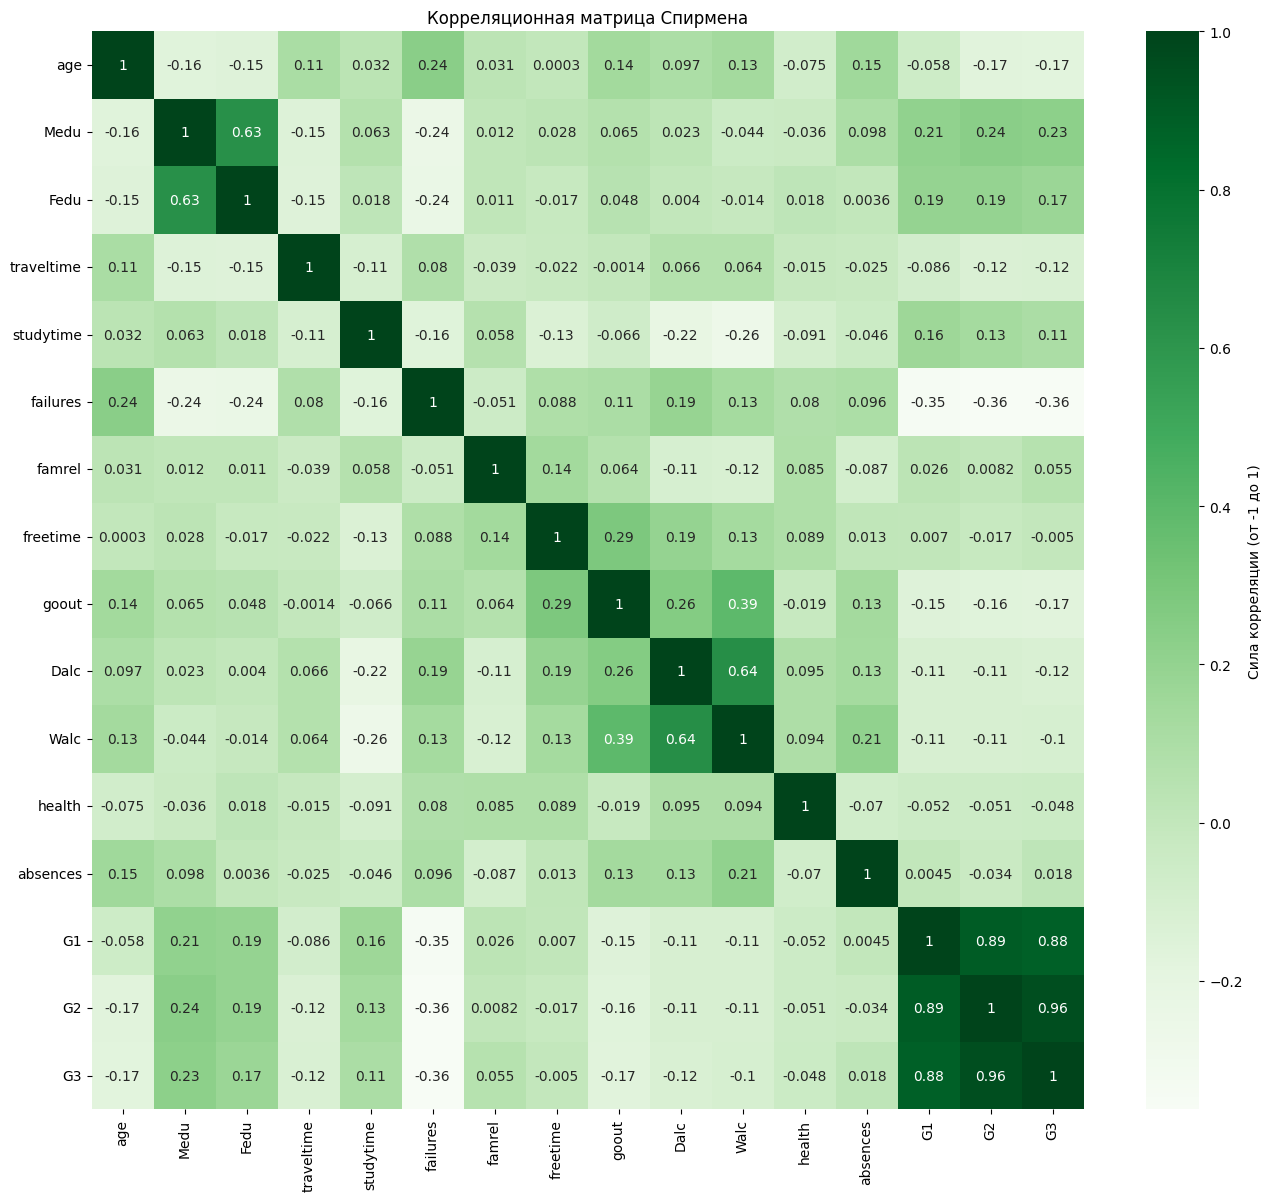

In [110]:
corr_matrix = df.corr(method='spearman', numeric_only=True)

plt.figure(figsize=(16, 14))

# Добавляем параметр cbar_kws с заголовком 'label'
sns.heatmap(corr_matrix, annot=True, cmap='Greens',
            cbar_kws={'label': 'Сила корреляции (от -1 до 1)'})

plt.title("Корреляционная матрица Спирмена")
plt.show()


### Корреляции признаков с G3

Смотрим, какие числовые признаки сильнее всего связаны с итоговой оценкой G3.

In [111]:
corr_with_target = corr_matrix["G3"].drop("G3")
corr_with_target.sort_values(ascending=False).head(15).round(3)

G2            0.957
G1            0.878
Medu          0.225
Fedu          0.170
studytime     0.105
famrel        0.055
absences      0.018
freetime     -0.005
health       -0.048
Walc         -0.104
traveltime   -0.121
Dalc         -0.121
goout        -0.166
age          -0.173
failures     -0.361
Name: G3, dtype: float64

### Положительные связи с G3

Отдельно выводим признаки, которые растут вместе с G3.

In [112]:
corr_with_target_plus = corr_with_target[corr_with_target > 0].sort_values(ascending=False).round(3)
corr_with_target_plus.head(6)

G2           0.957
G1           0.878
Medu         0.225
Fedu         0.170
studytime    0.105
famrel       0.055
Name: G3, dtype: float64

### Отрицательные связи с G3

Отдельно выводим признаки, которые связаны со снижением G3.

In [113]:
corr_with_target_minus = corr_with_target[corr_with_target < 0].sort_values(ascending=True).round(3)
corr_with_target_minus.head(7)

failures     -0.361
age          -0.173
goout        -0.166
Dalc         -0.121
traveltime   -0.121
Walc         -0.104
health       -0.048
Name: G3, dtype: float64

### Распределение целевой переменной

Строим гистограмму G3, чтобы увидеть, какие итоговые оценки встречаются чаще всего.

Text(0, 0.5, 'Количество студентов')

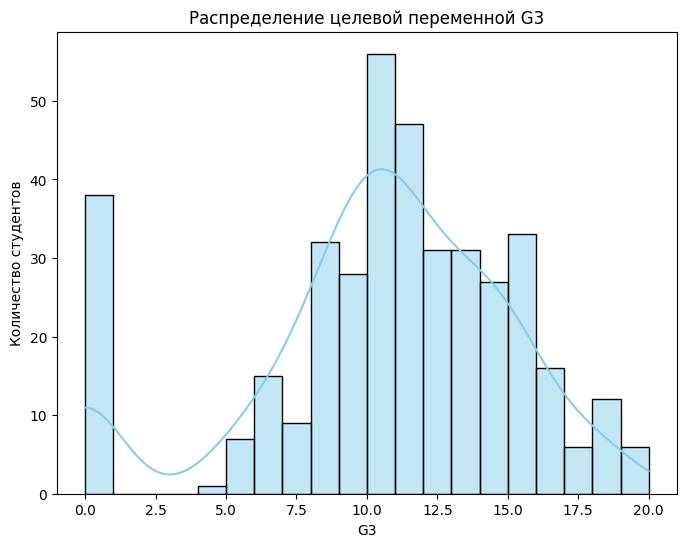

In [114]:
df_g3 = df[["G3"]]
plt.figure(figsize=(8, 6))
sns.histplot(df_g3["G3"], bins=20, kde=True, color="skyblue")
plt.title("Распределение целевой переменной G3")
plt.xlabel("G3")
plt.ylabel("Количество студентов")

### Статистика по G3

Смотрим минимум, максимум, среднее, медиану и квартили целевой переменной.

In [115]:
df["G3"].describe()

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

### Средняя G3 по количеству прошлых неудач

Проверяем, как меняется средняя итоговая оценка при разном значении failures.

In [116]:
df.groupby("failures")["G3"].mean()

failures
0    11.253205
1     8.120000
2     6.235294
3     5.687500
Name: G3, dtype: float64

### Средняя G3 по времени учебы

Сравниваем среднюю итоговую оценку для разных значений studytime.

In [117]:
df.groupby("studytime")["G3"].mean()

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64

### Средняя G3 по планам на высшее образование

Проверяем различие средней G3 между группами higher = yes и higher = no.

In [118]:
df.groupby("higher")["G3"].mean()

higher
no      6.800
yes    10.608
Name: G3, dtype: float64

## 2. Обучение и сравнение на двух датасетах

В этом разделе сравниваем простую baseline-модель и LinearRegression. Проверяем два сценария признаков: с промежуточными оценками G1/G2 и без них.

### 2.1 Основной датасет student_data.csv

Начинаем с маленького датасета, потому что на нем проще проверить логику обучения и интерпретировать результат.

### Импорт инструментов для обучения

Подключаем функции для train/test split, baseline-модель и метрики качества.

In [119]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Подготовка двух наборов признаков

Создаем два сценария: X_with_grades использует G1 и G2, а X_without_grades исключает их. Целевая переменная в обоих случаях - G3.

In [120]:
X_with_grades = df_encoding.drop(["G3"], axis=1)
X_without_grades = df_encoding.drop(["G1", "G2", "G3"], axis=1)
y = df_encoding["G3"]

### Train/test split для baseline с G1/G2

Делим данные на train и test для baseline-модели с промежуточными оценками.

In [121]:
X_train, X_test, y_train, y_test = train_test_split(
    X_with_grades,
    y,
    test_size=0.3,
    random_state=42)

### Dummy baseline с G1/G2

Обучаем простую baseline-модель, которая предсказывает среднее значение G3.

In [122]:
dummy_model_with_grades = DummyRegressor(strategy="mean")
dummy_model_with_grades.fit(X_train, y_train)

y_pred_dummy_with_grades = dummy_model_with_grades.predict(X_test)
print(f"Dummy model with grades")

Dummy model with grades


### Метрики Dummy baseline с G1/G2

Считаем MAE, RMSE и R2 для baseline-модели.

In [123]:
mae = mean_absolute_error(y_test, y_pred_dummy_with_grades)
rmse = mean_squared_error(y_test, y_pred_dummy_with_grades) ** 0.5
r2 = r2_score(y_test, y_pred_dummy_with_grades)

print(f"Dummy model with grades")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²: {r2:.3f}")

Dummy model with grades
MAE: 3.691
RMSE: 4.691
R²: -0.001


### Train/test split для baseline без G1/G2

Делим данные на train и test для baseline-модели без промежуточных оценок.

In [124]:
X_train, X_test, y_train, y_test = train_test_split(
    X_without_grades,
    y,
    test_size=0.3,
    random_state=42)

### Dummy baseline без G1/G2

Повторяем baseline для второго сценария. Для DummyRegressor результат ожидаемо такой же, потому что он не использует признаки.

In [125]:
dummy_model_without_grades = DummyRegressor(strategy="mean")
dummy_model_without_grades.fit(X_train, y_train)

y_pred_dummy_without_grades = dummy_model_without_grades.predict(X_test)
print(f"Dummy model without grades")

Dummy model without grades


### Метрики Dummy baseline без G1/G2

Считаем MAE, RMSE и R2 для baseline-модели во втором сценарии.

In [126]:
mae = mean_absolute_error(y_test, y_pred_dummy_without_grades)
rmse = mean_squared_error(y_test, y_pred_dummy_without_grades) ** 0.5
r2 = r2_score(y_test, y_pred_dummy_without_grades)

print(f"Dummy model without grades")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²: {r2:.3f}")

Dummy model without grades
MAE: 3.691
RMSE: 4.691
R²: -0.001


### Импорт cross-validation и LinearRegression

Подключаем cross-validation и простую линейную модель для сравнения с baseline.

In [127]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

### LinearRegression с G1/G2

Оцениваем линейную регрессию через 7-fold cross-validation по MAE.

In [128]:
model = LinearRegression()
linear_reg_mae_scores_with_grades = -cross_val_score(
    model,
    X_with_grades,
    y,
    cv=7,
    scoring='neg_mean_absolute_error')

linear_reg_mae_scores_with_grades.mean().round(3)

np.float64(1.371)

### LinearRegression без G1/G2

Повторяем cross-validation без промежуточных оценок, чтобы понять, насколько они важны для прогноза G3.

In [129]:
linear_reg_mae_scores_without_grades = -cross_val_score(
    model,
    X_without_grades,
    y,
    cv=7,
    scoring='neg_mean_absolute_error')

linear_reg_mae_scores_without_grades.mean().round(3)

np.float64(3.435)

### Визуальное сравнение MAE на основном датасете

Строим столбчатый график, чтобы сравнить baseline и LinearRegression в двух сценариях признаков. Чем ниже MAE, тем лучше.

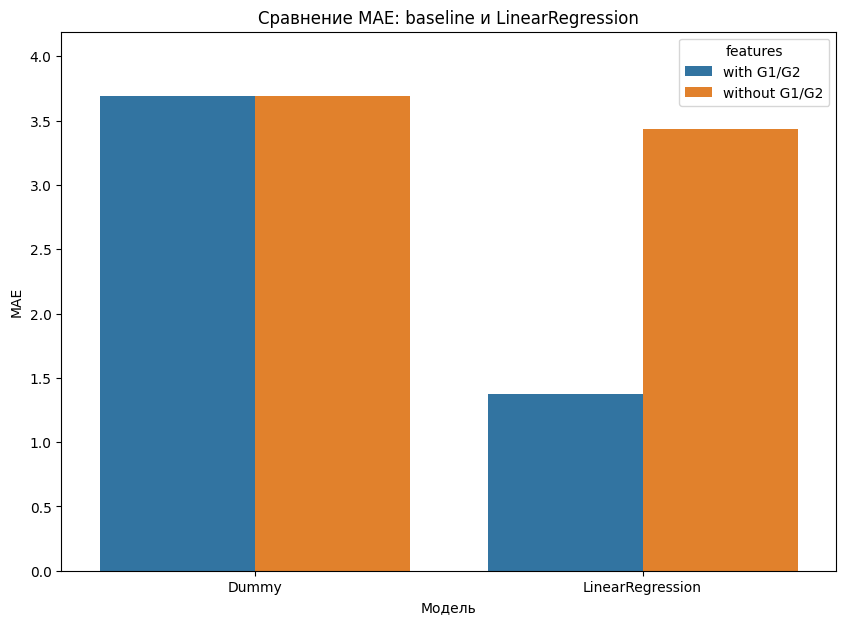

In [130]:
results = pd.DataFrame({
    "model": [
        "Dummy",
        "Dummy",
        "LinearRegression",
        "LinearRegression",
    ],
    "features": [
        "with G1/G2",
        "without G1/G2",
        "with G1/G2",
        "without G1/G2",
    ],
    "MAE": [
        3.691,
        3.691,
        linear_reg_mae_scores_with_grades.mean(),
        linear_reg_mae_scores_without_grades.mean(),
    ],
})

plt.figure(figsize=(10, 7))

sns.barplot(
    data=results,
    x="model",
    y="MAE",
    hue="features"
)

plt.title("Сравнение MAE: baseline и LinearRegression")
plt.xlabel("Модель")
plt.ylabel("MAE")
plt.ylim(0, results["MAE"].max() + 0.5)
plt.show()

### 2.2 Расширенный датасет student_data_500k.csv

Переходим к большому датасету. Не повторяем полный EDA, потому что структура почти такая же, а смотрим только ключевые проверки: загрузку, распределение G3, описательную статистику и сравнение моделей.

In [131]:
DATA_PATH = Path("../data/raw/student_data_500k.csv")
df_500 = pd.read_csv(DATA_PATH)
df_500.head()

,record_id,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,1,GP,F,15,U,GT3,T,2,3,other,...,2,5,1,1,1,5,0,8,7,6
1,2,GP,F,18,U,GT3,T,3,4,services,...,4,4,3,1,1,3,6,13,13,11
2,3,GP,M,18,U,GT3,T,2,1,other,...,5,2,4,1,2,4,8,14,13,12
3,4,GP,F,16,U,GT3,T,1,3,at_home,...,4,3,5,1,1,3,1,9,7,3
4,5,GP,M,16,U,GT3,T,1,0,other,...,4,3,2,1,1,3,4,13,14,12


### One-hot encoding для 500k и удаление record_id

Кодируем категориальные признаки и удаляем record_id, потому что это технический номер строки, а не характеристика студента.

In [132]:
df_500_encoding = pd.get_dummies(df_500, drop_first=True, dtype=int).drop(["record_id"], axis=1)

### Распределение G3 на 500k

Строим распределение целевой переменной на расширенном датасете.

Text(0, 0.5, 'Количество студентов')

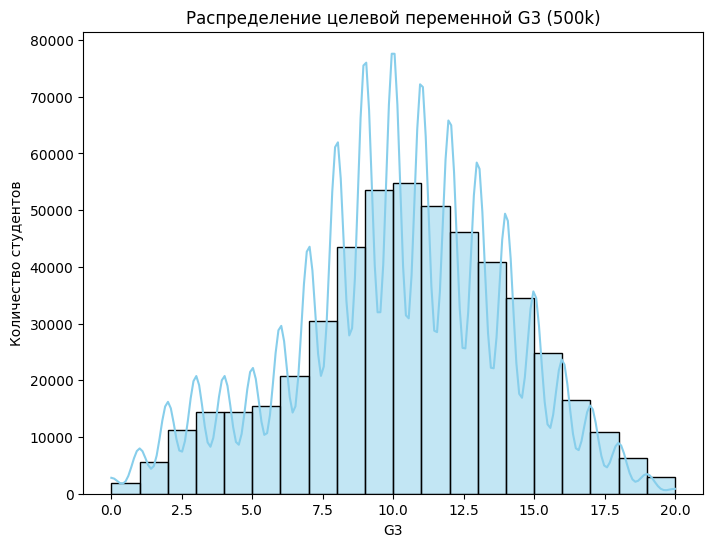

In [133]:
df_500_g3 = df_500[["G3"]]
plt.figure(figsize=(8, 6))
sns.histplot(df_500_g3["G3"], bins=20, kde=True, color="skyblue")
plt.title("Распределение целевой переменной G3 (500k)")
plt.xlabel("G3")
plt.ylabel("Количество студентов")

### Статистика G3 на 500k

Смотрим count, mean, std, min, max и квартили целевой переменной.

In [134]:
df_500_encoding["G3"].describe()

count    500000.000000
mean         10.082362
std           3.838412
min           0.000000
25%           8.000000
50%          10.000000
75%          13.000000
max          20.000000
Name: G3, dtype: float64

### Подготовка признаков для 500k

Создаем два сценария признаков: с G1/G2 и без G1/G2. Целевая переменная сохраняется отдельно как y_500.

In [135]:
X_500_with_grades = df_500_encoding.drop(["G3"], axis=1)
X_500_without_grades = df_500_encoding.drop(["G1", "G2", "G3"], axis=1)
y_500 = df_500_encoding["G3"]

### Dummy baseline на 500k

Считаем baseline через cross-validation. Одного baseline достаточно, потому что DummyRegressor не использует признаки.

In [136]:
DummyRegressor_mae_scores_500_grades = -cross_val_score(
    DummyRegressor(),
    X_500_with_grades,
    y_500,
    cv=7,
    scoring='neg_mean_absolute_error')

DummyRegressor_mae_scores_500_grades.mean().round(3)

np.float64(3.046)

### LinearRegression на 500k с G1/G2

Оцениваем линейную регрессию на расширенном датасете с промежуточными оценками.

In [137]:
model = LinearRegression()
linear_reg_mae_scores_500_with_grades = -cross_val_score(
    model,
    X_500_with_grades,
    y_500,
    cv=7,
    scoring='neg_mean_absolute_error')

linear_reg_mae_scores_500_with_grades.mean().round(3)

np.float64(1.165)

### LinearRegression на 500k без G1/G2

Оцениваем линейную регрессию без промежуточных оценок, чтобы сравнить силу остальных признаков.

In [138]:
linear_reg_mae_scores_500_without_grades = -cross_val_score(
    model,
    X_500_without_grades,
    y_500,
    cv=7,
    scoring='neg_mean_absolute_error')

linear_reg_mae_scores_500_without_grades.mean().round(3)

np.float64(2.619)

### Визуальное сравнение MAE на 500k

Строим график MAE для baseline и LinearRegression на расширенном датасете.

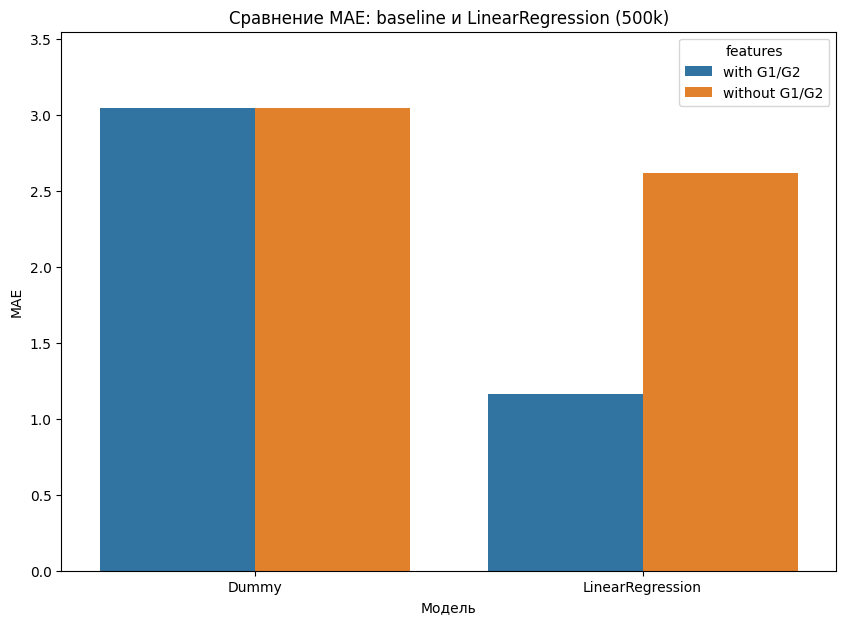

In [139]:
results = pd.DataFrame({
    "model": [
        "Dummy",
        "Dummy",
        "LinearRegression",
        "LinearRegression",
    ],
    "features": [
        "with G1/G2",
        "without G1/G2",
        "with G1/G2",
        "without G1/G2",
    ],
    "MAE": [
        3.046,
        3.046,
        linear_reg_mae_scores_500_with_grades.mean(),
        linear_reg_mae_scores_500_without_grades.mean(),
    ],
})

plt.figure(figsize=(10, 7))

sns.barplot(
    data=results,
    x="model",
    y="MAE",
    hue="features"
)

plt.title("Сравнение MAE: baseline и LinearRegression (500k)")
plt.xlabel("Модель")
plt.ylabel("MAE")
plt.ylim(0, results["MAE"].max() + 0.5)
plt.show()